In [1]:
import torch
import os
import glob
from PIL import Image
import numpy as np
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
from tqdm import tqdm

# --- IMPOSTAZIONE DEL DEVICE (GPU o CPU) ---
# Questa cella definisce il device una volta per tutte.
# Tutte le altre parti del codice useranno questa variabile.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device in uso: {device}")


print(f"Current working directory: {os.getcwd()}")

COLAB = False;
if COLAB:
    # Montiamo Google Drive
    from google.colab import drive
    drive.mount('/content/drive')

    # Definiamo il percorso principale
    DATASET_PATH = "/content/drive/MyDrive/Uni/Magistrale/colab/1/ML/Project/training/train"
else:
    DATASET_PATH = "../../dataset/training/train"

# Se si vuole eseguire tutto solo nel main
EXECUTE_MAIN = False;

Device in uso: cpu
Current working directory: c:\Users\Altair\Documents\GitHub\autoencoder-onboard-segmentation\notebooks\1 - Data Augmentation


# SegmentationDataset

In [2]:
# --- DEFINIZIONE DELLA CLASSE DATASET ---
import os
from PIL import Image
import numpy as np
import torch
from torch.utils.data import Dataset

class SegmentationDataset(Dataset):
    """
    Versione definitiva e semplificata del Dataset.
    Legge le immagini e le maschere che contengono già gli ID di classe.
    """
    def __init__(self, sample_dirs, transform=None):
        self.sample_dirs = sample_dirs
        self.transform = transform

    def __len__(self):
        return len(self.sample_dirs)

    def __getitem__(self, idx):
        sample_dir = self.sample_dirs[idx]

        img_path = os.path.join(sample_dir, 'rgb.jpg')
        mask_path = os.path.join(sample_dir, 'labels.png')

        # Carichiamo l'immagine RGB e la maschera
        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path) # È già in scala di grigi con indici 0-8

        # Convertiamo in array NumPy
        # Normalizziamo l'immagine a [0, 1] per la stabilità del training
        image_np = np.array(image, dtype=np.float32) / 255.0
        # Le maschere contengono ID, quindi usiamo un tipo intero
        mask_np = np.array(mask, dtype=np.int64)

        if self.transform:
            # Qui applicheremo la data augmentation nelle fasi successive
            pass

        # Convertiamo in tensori PyTorch
        # Immagine -> [C, H, W]
        image_tensor = torch.from_numpy(image_np).permute(2, 0, 1)
        # Maschera -> [H, W] (la loss CrossEntropy vuole questo formato)
        mask_tensor = torch.from_numpy(mask_np)

        return image_tensor, mask_tensor

In [3]:
import glob
from torch.utils.data import random_split
from typing import Tuple

def split_dataset(data_dir, batch_size) -> Tuple[DataLoader, DataLoader]:
  """
  Funzione per dividere il dataset in training e validation set.
  """

  # 1. Trova tutte le directory dei campioni
  all_sample_dirs = sorted(glob.glob(os.path.join(data_dir, "*")))
  print(f"Trovati {len(all_sample_dirs)} campioni totali.")

  # 2. Dividi le directory in training e validation set
  # Definiamo la dimensione del set di validazione (es. 20%)
  val_percent = 0.20
  n_val = int(len(all_sample_dirs) * val_percent)
  n_train = len(all_sample_dirs) - n_val

  # Usiamo random_split per creare due sotto-liste di percorsi
  # impostiamo un generator per la riproducibilità dello split
  generator = torch.Generator().manual_seed(42)
  train_dirs, val_dirs = random_split(all_sample_dirs, [n_train, n_val], generator=generator)

  print(f"Numero di campioni per training: {len(train_dirs)}")
  print(f"Numero di campioni per validazione: {len(val_dirs)}")

  # 3. Creiamo le istanze dei due Dataset
  train_dataset = SegmentationDataset(sample_dirs=list(train_dirs))
  val_dataset = SegmentationDataset(sample_dirs=list(val_dirs))

  # 4. Creiamo i DataLoader
  # Il DataLoader si occuperà di creare i batch e mescolare i dati
  train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
  val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
  return train_loader, val_loader


if not EXECUTE_MAIN:
  train_loader, val_loader = split_dataset(DATASET_PATH, 4)

Trovati 931 campioni totali.
Numero di campioni per training: 745
Numero di campioni per validazione: 186


# Calcolo della distribuzione del dataset



### Cosa posso concludere guardando questa matrice? (Analisi e Conclusioni)

La matrice mostra quante immagini contengono *contemporaneamente* due classi. L'elemento sulla diagonale (es. Classe 0, Classe 0) indica il numero totale di immagini che contengono la Classe 0.

1.  **Forte Sbilanciamento del Dataset (Class Imbalance):**
    *   Guardando la diagonale, si nota subito una grande disparità nel numero di campioni per classe.
    *   **Classi Dominanti:** `Classe 0` (931 immagini), `Classe 7` (923 immagini) e `Classe 8` (844 immagini) sono estremamente ben rappresentate.
    *   **Classe Rarissima:** `Classe 4` è presente in sole **42 immagini**. Questa è una "mosca bianca" nel dataset e sarà molto difficile per qualsiasi modello imparare a riconoscerla correttamente.
    *   **Classi Intermedie:** Le altre classi hanno una rappresentazione media o medio-bassa (es. `Classe 5` con 164, `Classe 6` con 355).

2.  **Fortissime Correlazioni tra Classi (Co-occorrenze):**
    *   Esistono coppie di classi che appaiono quasi sempre insieme. Questo è l'insight più importante.
    *   **Il Trio Inseparabile {0, 7, 8}:**
        *   La co-occorrenza tra `Classe 0` e `Classe 7` è **923**. Su 931 immagini con la classe 0, 923 contengono anche la classe 7 (99%!). E viceversa.
        *   Similmente, le co-occorrenze tra (0, 8) e (7, 8) sono altissime (844 e 836).
    *   **Conclusione:** Le classi 0, 7 e 8 descrivono oggetti o concetti che esistono quasi sempre nello stesso contesto. Potrebbero essere, ad esempio, "strada", "cielo" e "auto" in un dataset di guida autonoma. Sono semanticamente legate.

3.  **Altri Gruppi di Co-occorrenza:**
    *   Si notano altre co-occorrenze significative, anche se meno estreme. Per esempio, la `Classe 2` co-occorre spesso con la `Classe 0` (642) e la `Classe 7` (637). Questo suggerisce che anche la Classe 2 fa parte spesso del "contesto" definito dal trio {0, 7, 8}.

4.  **Classi più "Isolate":**
    *   La `Classe 4`, a causa della sua rarità, co-occorre molto poco con le altre. Il valore massimo di co-occorrenza è con la `Classe 0` e la `Classe 7` (42), che è semplicemente il numero totale delle sue immagini.
    *   La `Classe 5` (164 immagini) sembra avere legami più deboli con le altre classi rispetto, ad esempio, alla `Classe 2` o `Classe 3`.

---

### Che cosa posso fare per ottimizzare il mio modello?

Basandosi su queste conclusioni, ecco delle strategie concrete:

1.  **Gestire lo Sbilanciamento delle Classi:**
    *   **Data Augmentation Selettiva:** Applica tecniche di augmentation (rotazioni, flip, cambi di colore, cutout, ecc.) in modo molto più aggressivo sulle immagini che contengono la `Classe 4` e, in misura minore, la `Classe 5`.
    *   **Ricampionamento (Resampling):**
        *   **Sovra-campionamento (Oversampling):** Duplica (o genera sinteticamente con tecniche come SMOTE) i campioni delle classi rare (`Classe 4`, `Classe 5`).
        *   **Sotto-campionamento (Undersampling):** Rimuovi casualmente alcuni campioni delle classi dominanti (`Classe 0`, `7`, `8`). Attenzione: questo può portare a una perdita di informazione.
    *   **Loss Function Ponderata (Weighted Loss):** Modifica la funzione di costo del tuo modello per dare un "peso" maggiore agli errori commessi sulla `Classe 4`. In questo modo, il modello sarà penalizzato di più se sbaglia una classe rara e sarà incentivato a impararla.

2.  **Sfruttare le Co-occorrenze:**
    *   **Considerare il Problema come Multi-Label:** Questa non è una classica classificazione dove un'immagine ha una sola etichetta. È un problema di **classificazione multi-etichetta (multi-label)**. Assicurati che il tuo modello e la tua loss function siano adatti a questo (es. `BinaryCrossentropy` su ogni output invece di `CategoricalCrossentropy`).
    *   **Creare "Super-Classi" o Classi Gerarchiche:**
        *   **Semplificazione:** Visto che {0, 7, 8} sono quasi sempre insieme, potresti provare a unirle in una singola "Super-Classe_A". Questo semplifica il problema per il modello, anche se perdi granularità. Può essere un buon test per vedere se le performance generali migliorano.
        *   **Approccio Gerarchico:** Addestra un primo modello che riconosce il "contesto" (es. "Contesto A" se sono presenti {0,7,8}, "Contesto B" altrimenti). Poi, un secondo modello specializzato a trovare le classi più fini all'interno di quel contesto.
    *   **Modelli Basati su Grafi (Graph Neural Networks):** Un approccio avanzato potrebbe essere quello di modellare le relazioni tra le classi usando un grafo, dove le co-occorrenze definiscono i pesi degli archi, e usare questa informazione per raffinare le predizioni del modello.

---

### Che altre dinamiche si aprono? Cosa aggiunge alla situazione?

Questa matrice cambia la prospettiva da "il mio modello è accurato al X%?" a domande molto più profonde:

1.  **Comprensione del Dominio e del Bias dei Dati:** La matrice non descrive il tuo modello, ma **il tuo dataset**. Rivela i bias intrinseci del mondo reale (o di come hai raccolto i dati). Le classi {0, 7, 8} appaiono insieme non per caso, ma perché il mondo che fotografi è fatto così. Questo è un insight fondamentale.

2.  **Strategia di Validazione (Train/Test Split):** Un semplice split casuale del dataset è pericoloso. Potresti finire con tutte le 42 immagini della `Classe 4` nel set di training e nessuna nel set di test, rendendo impossibile valutarne la performance. Devi usare uno **split stratificato (stratified split)** che mantenga le proporzioni delle singole classi in entrambi i set. Per problemi multi-label, esistono tecniche di stratificazione più complesse (es. *iterative stratification*) che cercano di preservare anche le combinazioni di etichette.

3.  **Post-Processing delle Predizioni:** Puoi usare questa matrice come una "conoscenza a priori". Se il tuo modello predice `Classe 0` con alta probabilità ma `Classe 7` con bassa probabilità, puoi usare questa informazione per:
    *   Aumentare artificialmente la probabilità della `Classe 7`.
    *   Segnalare questa predizione come "potenzialmente incoerente" e degna di un controllo manuale.

4.  **Definizione degli Obiettivi di Business:** Questa analisi potrebbe portare a una discussione con gli stakeholder. È davvero cruciale distinguere tra `Classe 0`, `7` e `8`, o è sufficiente sapere che siamo in quel "contesto"? La risposta a questa domanda può cambiare radicalmente la definizione del problema e le metriche di successo.

In sintesi, questa matrice trasforma la "scatola nera" dei dati in una mappa dettagliata che ti guida verso strategie mirate, ti fa dubitare delle metriche superficiali e ti costringe a comprendere la struttura intrinseca del tuo problema.asse 0, 923 contengono anche la classe 7 (99%!). E viceversa.
Similmente, le co-occorrenze tra (0, 8) e (7, 8) sono altissime (844 e 836).
Conclusione: Le classi 0, 7 e 8 descrivono oggetti o concetti che esistono quasi sempre nello stesso contesto. Potrebbero essere, ad esempio, "strada", "cielo" e "auto" in un dataset di guida autonoma. Sono semanticamente legate.
Altri Gruppi di Co-occorrenza:
Si notano altre co-occorrenze significative, anche se meno estreme. Per esempio, la Classe 2 co-occorre spesso con la Classe 0 (642) e la Classe 7 (637). Questo suggerisce che anche la Classe 2 fa parte spesso del "contesto" definito dal trio {0, 7, 8}.
Classi più "Isolate":
La Classe 4, a causa della sua rarità, co-occorre molto poco con le altre. Il valore massimo di co-occorrenza è con la Classe 0 e la Classe 7 (42), che è semplicemente il numero totale delle sue immagini.
La Classe 5 (164 immagini) sembra avere legami più deboli con le altre classi rispetto, ad esempio, alla Classe 2 o Classe 3.


# Data Augmentation

In [7]:
import torch
from tqdm import tqdm
import os

def get_representative_images_per_class(dataset, num_classes, class_names, top_n=5):
    """
    Analizza il dataset per trovare le 'top_n' immagini più rappresentative per ogni classe.

    Args:
        dataset (Dataset): L'istanza del dataset completo.
        num_classes (int): Il numero di classi totali.
        class_names (list): La lista dei nomi delle classi.
        top_n (int): Il numero di immagini da mostrare per ogni classe.
    """
    print(f"Inizio analisi per trovare le {top_n} immagini più rappresentative per classe...")

    class_images = [[] for _ in range(num_classes)]

    for i in tqdm(range(len(dataset)), desc="Analisi Immagini"):
        _, mask = dataset[i]
        total_pixels_in_mask = mask.numel()
        if total_pixels_in_mask == 0:
            continue
        counts = torch.bincount(mask.flatten(), minlength=num_classes)
        for class_id in range(num_classes):
            if counts[class_id] > 0:
                percentage = 100.0 * counts[class_id] / total_pixels_in_mask
                sample_path = dataset.sample_dirs[i]
                class_images[class_id].append((percentage, sample_path))

    print("\nAnalisi completata. Ordino e stampo i risultati...")

    # Ordinamento e Stampa
    for class_id in range(num_classes):
        print("-" * 50)
        print(f"CLASSE: {class_names[class_id].upper()} ({class_id})")
        print("-" * 50)

        sorted_images = sorted(class_images[class_id], key=lambda x: x[0], reverse=True)

        if not sorted_images:
            print("Nessuna immagine trovata per questa classe.")
            continue

        # Stampa solo i primi 'top_n' elementi
        for idx, (percentage, path) in enumerate(sorted_images[:top_n]):
            print(f"{idx + 1}. {os.path.basename(path)} (presenza: {percentage:.2f}%)")



print("--- STAMPA SOLO LA MIGLIORE IMMAGINE PER CLASSE ---")
get_representative_images_per_class(full_dataset, num_classes=9, class_names=class_names, top_n=1)



--- STAMPA SOLO LA MIGLIORE IMMAGINE PER CLASSE ---
Inizio analisi per trovare le 1 immagini più rappresentative per classe...


Analisi Immagini: 100%|██████████| 931/931 [00:10<00:00, 89.19it/s]


Analisi completata. Ordino e stampo i risultati...
--------------------------------------------------
CLASSE: CLASSE 0 (0)
--------------------------------------------------
1. 0546 (presenza: 44.05%)
--------------------------------------------------
CLASSE: CLASSE 1 (1)
--------------------------------------------------
1. 0312 (presenza: 66.15%)
--------------------------------------------------
CLASSE: CLASSE 2 (2)
--------------------------------------------------
1. 0833 (presenza: 73.56%)
--------------------------------------------------
CLASSE: CLASSE 3 (3)
--------------------------------------------------
1. 1147 (presenza: 66.82%)
--------------------------------------------------
CLASSE: CLASSE 4 (4)
--------------------------------------------------
1. 0305 (presenza: 19.65%)
--------------------------------------------------
CLASSE: CLASSE 5 (5)
--------------------------------------------------
1. 0531 (presenza: 39.47%)
------------------------------------------------

# Smart Split

In [9]:
import numpy as np
import torch
from torch.utils.data import Subset
from skmultilearn.model_selection import iterative_train_test_split
from tqdm import tqdm
import os # Già importato nel tuo codice

# Assumiamo che tu abbia queste variabili definite
# full_dataset = ...
# num_classes = 9
# class_names = [...]

def create_multilabel_stratified_split(dataset, num_classes, test_size=0.2):
    """
    Crea uno split train/validation stratificato per un problema multi-label.
    
    Args:
        dataset (torch.utils.data.Dataset): Il dataset completo. L'indicizzazione 
                                            dataset[i] deve restituire (image, mask).
        num_classes (int): Il numero totale di classi nel dataset.
        test_size (float): La proporzione del dataset da allocare al set di validazione.

    Returns:
        tuple: Una tupla contenente (train_dataset, validation_dataset) come Subset di PyTorch.
    """
    
    # --- FASE 1: Estrazione delle etichette da ogni maschera ---
    print("Fase 1: Estrazione delle etichette multi-label dal dataset...")
    num_samples = len(dataset)
    # Creiamo una matrice (n_samples, n_classes) per skmultilearn
    y = np.zeros((num_samples, num_classes), dtype=int)

    for i in tqdm(range(num_samples), desc="Scansione maschere"):
        # Assumiamo che il dataset restituisca (immagine, maschera)
        _, mask = dataset[i]
        if mask.numel() > 0:
            # torch.bincount è un modo efficiente per contare le occorrenze di ogni classe
            counts = torch.bincount(mask.flatten(), minlength=num_classes)
            # Una classe è presente se il suo conteggio è > 0
            y[i, :] = (counts > 0).numpy().astype(int)

    # --- FASE 2: Esecuzione dello split stratificato iterativo ---
    print(f"\nFase 2: Esecuzione dello split stratificato (test_size={test_size})...")
    
    # iterative_split ha bisogno di un input X, ma noi siamo interessati solo a splittare 
    # gli indici. Quindi creiamo un array di indici fittizio.
    X_indices = np.arange(num_samples).reshape(-1, 1)
    
    # La funzione restituisce gli indici per train e test
    # L'output è (X_train, y_train, X_test, y_test) ma X contiene i nostri indici
    train_indices, _, val_indices, _ = iterative_train_test_split(X_indices, y, test_size=test_size)
    
    # Gli indici sono restituiti come array 2D, li appiattiamo
    train_indices = train_indices.flatten()
    val_indices = val_indices.flatten()

    # --- FASE 3: Creazione dei Dataset di tipo Subset ---
    print("\nFase 3: Creazione dei Dataset di tipo Subset...")
    train_subset = Subset(dataset, train_indices)
    val_subset = Subset(dataset, val_indices)
    
    print("-" * 50)
    print("Split completato con successo!")
    print(f"  - Dataset di training: {len(train_subset)} campioni")
    print(f"  - Dataset di validazione: {len(val_subset)} campioni")
    print("-" * 50)
    
    return train_subset, val_subset

def verify_split_distribution(dataset, class_names, title="Distribuzione"):
    """
    Funzione di utilità per verificare la distribuzione delle classi in un dataset (o subset).
    """
    num_classes = len(class_names)
    num_samples = len(dataset)
    class_counts = np.zeros(num_classes, dtype=int)
    
    for i in range(num_samples):
        _, mask = dataset[i]
        if mask.numel() > 0:
            counts = torch.bincount(mask.flatten(), minlength=num_classes)
            class_counts += (counts > 0).numpy().astype(int)
            
    print(f"\n--- {title} ({num_samples} campioni) ---")
    for i, count in enumerate(class_counts):
        percentage = 100 * count / num_samples
        print(f"  - {class_names[i]:<15} ({i}): {count:<5} campioni ({percentage:.2f}%)")



# --- ESEMPIO DI UTILIZZO ---

# 1. Esegui lo split
# Assumiamo che 'full_dataset', 'num_classes', e 'class_names' siano già definiti
train_dataset, val_dataset = create_multilabel_stratified_split(
    dataset=full_dataset, 
    num_classes=len(class_names), 
    test_size=0.2
)

# 2. (Opzionale ma Raccomandato) Verifica le distribuzioni
# Se lo split è buono, le percentuali per ogni classe dovrebbero essere molto simili
# tra il set di training e quello di validazione.
print("\n\n--- VERIFICA DELLA DISTRIBUZIONE DELLO SPLIT ---")
verify_split_distribution(train_dataset, class_names, title="Distribuzione nel TRAINING set")
verify_split_distribution(val_dataset, class_names, title="Distribuzione nel VALIDATION set")
verify_split_distribution(full_dataset, class_names, title="Distribuzione nel FULL set (Originale)")

# Ora puoi usare train_dataset e val_dataset per creare i tuoi DataLoader
# train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=..., shuffle=True)
# val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=..., shuffle=False)

Fase 1: Estrazione delle etichette multi-label dal dataset...


Scansione maschere: 100%|██████████| 931/931 [00:10<00:00, 91.53it/s]



Fase 2: Esecuzione dello split stratificato (test_size=0.2)...

Fase 3: Creazione dei Dataset di tipo Subset...
--------------------------------------------------
Split completato con successo!
  - Dataset di training: 745 campioni
  - Dataset di validazione: 186 campioni
--------------------------------------------------


--- VERIFICA DELLA DISTRIBUZIONE DELLO SPLIT ---

--- Distribuzione nel TRAINING set (745 campioni) ---
  - Classe 0        (0): 745   campioni (100.00%)
  - Classe 1        (1): 439   campioni (58.93%)
  - Classe 2        (2): 514   campioni (68.99%)
  - Classe 3        (3): 419   campioni (56.24%)
  - Classe 4        (4): 33    campioni (4.43%)
  - Classe 5        (5): 128   campioni (17.18%)
  - Classe 6        (6): 270   campioni (36.24%)
  - Classe 7        (7): 738   campioni (99.06%)
  - Classe 8        (8): 681   campioni (91.41%)

--- Distribuzione nel VALIDATION set (186 campioni) ---
  - Classe 0        (0): 186   campioni (100.00%)
  - Classe 1        (

Domanda eccellente. È il tipo di domanda critica che distingue un buon data scientist. Mette in discussione un'assunzione di base e ti costringe a giustificarla.

Hai parzialmente ragione: se il tuo processo di training è abbastanza lungo e robusto, e i tuoi `DataLoader` mescolano bene i dati (`shuffle=True`), il modello alla fine "vedrà" tutti i campioni, indipendentemente dallo split iniziale.

Tuttavia, stai confondendo due problemi fondamentalmente diversi:
1.  **Come il modello impara** (il processo di training sul `train_set`).
2.  **Come misuriamo *onestamente* se sta imparando bene** (il processo di validazione sul `val_set`).

**La vera ragione per uno split intelligente non è aiutare il modello a imparare, ma potersi fidare delle metriche di validazione.**

Facciamo un'analogia:

*   **Dataset di training:** I libri di testo e i compiti a casa di uno studente.
*   **Data Augmentation:** Lo studente che decide di passare più tempo a studiare i capitoli difficili e rari (la `Classe 4`).
*   **Dataset di validazione:** L'esame finale, che dovrebbe testare la conoscenza su *tutto* il programma.

Ora, cosa succede con uno split casuale (non intelligente)?

### Scenario da Incubo 1: Validazione "Fortunata" ma Inutile

Con uno split 80/20 casuale, è statisticamente possibile (e con classi così rare, quasi probabile) che **tutte le 42 immagini della `Classe 4` finiscano nel set di training**.

*   **Cosa succede?**
    *   Il tuo set di validazione non ha **nessun esempio** della `Classe 4`.
    *   Durante la validazione, il tuo modello otterrà una precisione/recall/F1-score del 100% (o non sarà proprio calcolata) per la `Classe 4`, semplicemente perché non viene mai testato su di essa.
    *   Le tue curve di validazione (loss, accuracy) sembreranno fantastiche. Penserai: "Wow, il mio modello sta generalizzando benissimo!".
    *   **La realtà:** Non hai la più pallida idea di come il tuo modello si comporterà sulla `Classe 4`. Hai creato un esame finale che "dimentica" di fare domande sul capitolo più difficile. Quando andrai in produzione (il mondo reale), il modello fallirà miseramente ogni volta che incontrerà un'immagine con la `Classe 4`.

### Scenario da Incubo 2: Training Impossibile

Meno probabile, ma catastrofico. Immagina che la maggior parte delle immagini della `Classe 4` finisca nel set di validazione.

*   **Cosa succede?**
    *   Il tuo modello non ha quasi nessun esempio su cui allenarsi per la `Classe 4`.
    *   Durante la validazione, le sue performance sulla `Classe 4` saranno zero.
    *   Penserai che il tuo modello non è in grado di imparare, che la tua architettura è sbagliata, e magari abbandonerai l'approccio, quando in realtà non gli hai mai dato il materiale corretto per studiare.

### La Soluzione: Due Strumenti per Due Scopi Diversi

Non è un approccio ibrido. **Sono due strumenti che risolvono due problemi diversi e sequenziali.**

1.  **Split Intelligente (Stratificato):**
    *   **Scopo:** Creare un "esame" (`val_set`) che sia una miniatura fedele e rappresentativa del problema reale. Garantisce che la distribuzione delle classi (singole e in combinazione) nel set di validazione rispecchi quella del set di training.
    *   **Risultato:** Quando guardi la loss di validazione, **sai che stai misurando qualcosa di significativo**. Se la metrica per la `Classe 4` migliora, è perché il modello sta davvero imparando a riconoscerla sui pochi esempi che hai messo da parte *apposta* per il test.

2.  **Data Augmentation / Ponderazione della Loss (SOLO sul `train_set`):**
    *   **Scopo:** "Truccare" il materiale di studio (`train_set`) per costringere il modello a prestare attenzione alle classi rare che altrimenti ignorerebbe. È qui che bilanci le classi.
    *   **Risultato:** Il modello impara in modo più robusto.

**In sintesi:**

> Usi lo **split intelligente** per essere sicuro che l'esame sia giusto.
> Usi la **data augmentation** per essere sicuro che lo studente studi per quell'esame nel modo più efficace.

Fare una cosa senza l'altra è pericoloso. Senza lo split intelligente, non puoi fidarti dei tuoi risultati. Senza la data augmentation, il modello non imparerà bene, anche se l'esame è giusto. Devi farle entrambe.

# Analisi Pre data augmentation

--- AVVIO ANALISI DI CONTESTO COMPLETA PER TUTTE LE CLASSI ---

Processing Target: Classe 0


-> Analisi per Classe 0 completata. Trovata in 931 immagini.

Processing Target: Classe 1


-> Analisi per Classe 1 completata. Trovata in 549 immagini.

Processing Target: Classe 2


-> Analisi per Classe 2 completata. Trovata in 642 immagini.

Processing Target: Classe 3


-> Analisi per Classe 3 completata. Trovata in 520 immagini.

Processing Target: Classe 4


-> Analisi per Classe 4 completata. Trovata in 42 immagini.

Processing Target: Classe 5


-> Analisi per Classe 5 completata. Trovata in 164 immagini.

Processing Target: Classe 6


-> Analisi per Classe 6 completata. Trovata in 355 immagini.

Processing Target: Classe 7


-> Analisi per Classe 7 completata. Trovata in 923 immagini.

Processing Target: Classe 8


-> Analisi per Classe 8 completata. Trovata in 844 immagini.


--- TABELLA DI CONFRONTO COMPLETA DEI CONTESTI (Trasposta) ---
Ogni RIGA mostra la composizione media di un'immagine che contiene la classe target indicata.
             Classe 0  Classe 1  Classe 2  Classe 3  Classe 4  Classe 5  Classe 6  Classe 7  Classe 8
Contesto C0     2.86%    15.04%    13.36%    15.20%     0.18%     0.87%     6.24%    36.06%    10.19%
Contesto C1     2.94%    25.51%    10.84%     3.71%     0.21%     0.83%     6.61%    39.52%     9.82%
Contesto C2     2.42%    11.70%    19.38%    15.67%     0.14%     0.59%     3.30%    36.13%    10.68%
Contesto C3     3.09%     8.97%    11.69%    27.21%     0.09%     1.11%     6.42%    31.08%    10.34%
Contesto C4     4.15%    21.48%     5.81%    12.42%     4.08%     1.96%     6.47%    37.77%     5.86%
Contesto C5     3.60%    21.19%    14.14%    11.21%     0.24%     4.91%     5.46%    29.45%     9.80%
Contesto C6     3.37%    16.17%     6.67%    15.34%     0.24%     

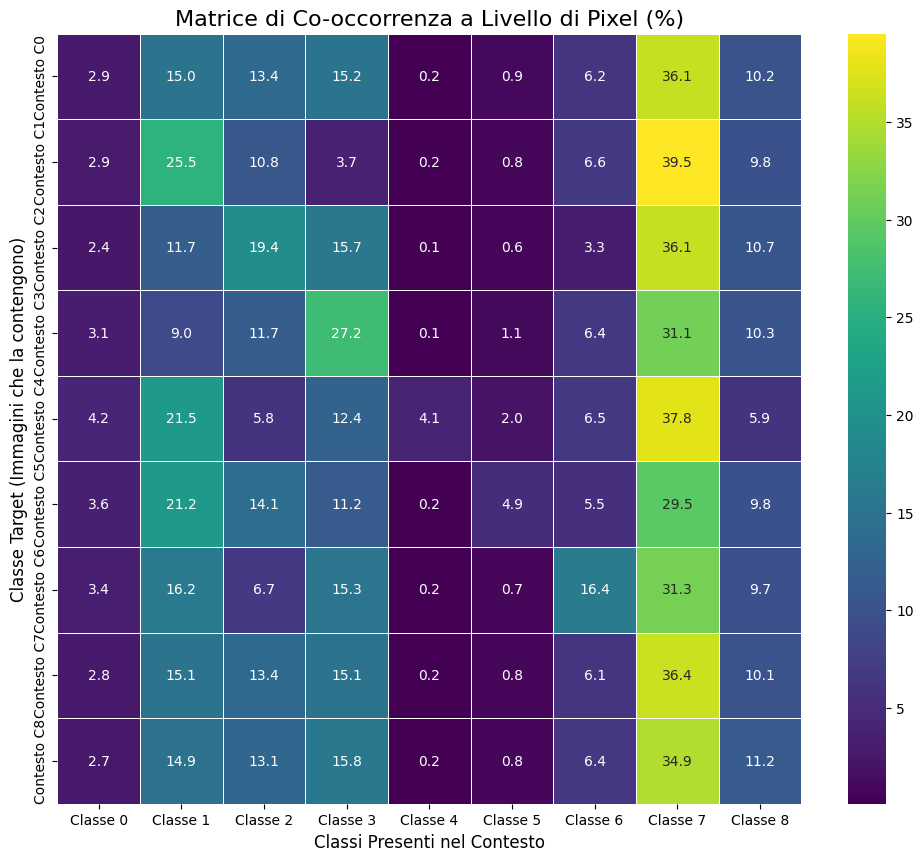

In [10]:
import numpy as np
import os
import glob
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import pandas as pd

def analyze_class_context(dataset_path, target_class_id, num_classes=9):
    """
    Analizza il contesto di una classe target.
    (Questa funzione rimane invariata)
    """
    
    total_pixel_counts_in_subset = np.zeros(num_classes, dtype=np.int64)
    num_images_in_subset = 0
    
    all_sample_dirs = sorted(glob.glob(os.path.join(dataset_path, "*")))

    # Il desc della TQDM ora è più generico perché verrà chiamato in un ciclo
    for sample_dir in tqdm(all_sample_dirs, desc=f"Scansione (Target: {target_class_id})", leave=False):
        mask_path = os.path.join(sample_dir, 'labels.png')
        if not os.path.exists(mask_path): continue
        
        mask = np.array(Image.open(mask_path))
        
        unique_classes = np.unique(mask)
        if target_class_id not in unique_classes:
            continue
            
        num_images_in_subset += 1
        
        counts = np.bincount(mask.flatten(), minlength=num_classes)
        total_pixel_counts_in_subset += counts

    if num_images_in_subset == 0:
        return None, 0

    total_pixels_in_subset = total_pixel_counts_in_subset.sum()
    if total_pixels_in_subset == 0:
        return None, num_images_in_subset
        
    avg_distribution = (total_pixel_counts_in_subset / total_pixels_in_subset) * 100
    
    class_names = [f"Classe {i}" for i in range(num_classes)]
    distribution_series = pd.Series(avg_distribution, index=class_names, name=f"Contesto Classe {target_class_id}")
    
    return distribution_series, num_images_in_subset


# --- Esecuzione dell'Analisi Completa ---

SOURCE_DATASET_PATH = "../../dataset/training/train"
NUM_CLASSES = 9

# Ora iteriamo su TUTTE le classi da 0 a 8
all_classes_to_analyze = range(NUM_CLASSES) 
context_results_full = {}

print("--- AVVIO ANALISI DI CONTESTO COMPLETA PER TUTTE LE CLASSI ---")
for class_id in all_classes_to_analyze:
    print(f"\nProcessing Target: Classe {class_id}")
    result, num_images = analyze_class_context(SOURCE_DATASET_PATH, class_id, NUM_CLASSES)
    if result is not None:
        context_results_full[f"Contesto C{class_id}"] = result
        print(f"-> Analisi per Classe {class_id} completata. Trovata in {num_images} immagini.")
    else:
        print(f"-> Classe {class_id} non trovata in nessuna immagine.")

# Creiamo un DataFrame per confrontare facilmente i risultati
if context_results_full:
    comparison_df_full = pd.DataFrame(context_results_full)
    
    # Per una migliore leggibilità, è meglio visualizzare la tabella trasposta
    # righe = classi target, colonne = classi presenti nel contesto
    comparison_df_transposed = comparison_df_full.transpose()
    
    print("\n\n--- TABELLA DI CONFRONTO COMPLETA DEI CONTESTI (Trasposta) ---")
    print("Ogni RIGA mostra la composizione media di un'immagine che contiene la classe target indicata.")
    print(comparison_df_transposed.to_string(float_format="%.2f%%"))

    # Visualizzazione con una Heatmap
    # Una heatmap è molto più efficace di un bar chart con così tanti dati
    plt.figure(figsize=(12, 10))
    # Usiamo la tabella trasposta per avere i target sull'asse Y
    sns.heatmap(
        comparison_df_transposed, 
        annot=True, 
        fmt=".1f", # Mostra una cifra decimale
        cmap='viridis', 
        linewidths=.5
    )
    plt.title('Matrice di Co-occorrenza a Livello di Pixel (%)', fontsize=16)
    plt.xlabel('Classi Presenti nel Contesto', fontsize=12)
    plt.ylabel('Classe Target (Immagini che la contengono)', fontsize=12)
    plt.show()

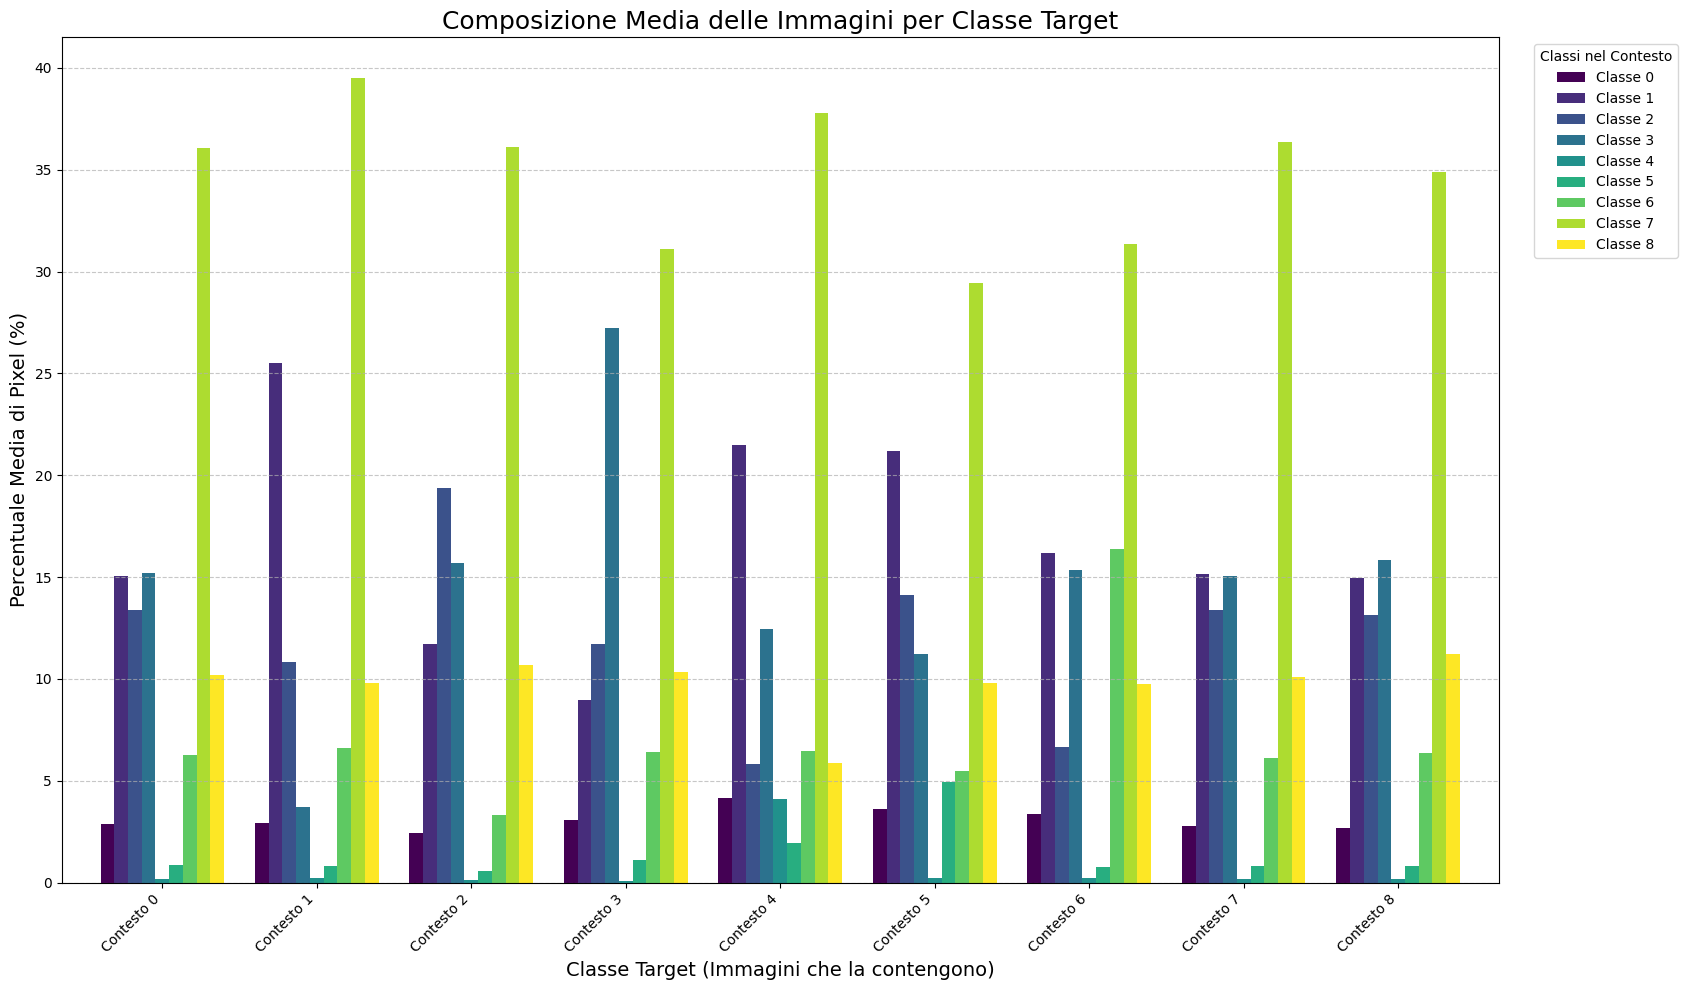

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

# Assumiamo che 'comparison_df_full' sia il DataFrame che hai generato
# con l'analisi completa. Se non lo hai più in memoria, dovrai rieseguire
# la parte di analisi dello script precedente per ricalcolarlo.

# Esempio di come potrebbe essere il DataFrame (per far funzionare il codice da solo)
# Sostituisci questo con il tuo vero DataFrame se necessario
# data = {'Contesto C0': {'Classe 0': 2.9, 'Classe 1': 15.0, ...}, ...}
# comparison_df_full = pd.DataFrame(data)


# --- GENERAZIONE DEL GRAFICO A BARRE RAGGRUPPATE ---

if 'comparison_df_full' in locals() or 'comparison_df_full' in globals():
    # Trasponiamo il DataFrame per avere le classi target come gruppi sull'asse x
    # e le classi di contesto come barre individuali.
    df_for_plot = comparison_df_full.transpose()

    # Creiamo il grafico
    ax = df_for_plot.plot(
        kind='bar',
        figsize=(20, 10),
        width=0.8,
        colormap='viridis' # Usiamo lo stesso schema di colori della heatmap per coerenza
    )

    # Impostazioni per migliorare la leggibilità
    plt.title('Composizione Media delle Immagini per Classe Target', fontsize=18)
    plt.ylabel('Percentuale Media di Pixel (%)', fontsize=14)
    plt.xlabel('Classe Target (Immagini che la contengono)', fontsize=14)

    # Aggiusta le etichette dell'asse x
    # Estrae i nomi delle classi target (es. 'C0', 'C1') e li formatta
    xtick_labels = [f"Contesto {col.replace('Contesto C', '')}" for col in comparison_df_full.columns]
    ax.set_xticklabels(xtick_labels, rotation=45, ha="right")
    
    plt.legend(title='Classi nel Contesto', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout(rect=[0, 0, 0.85, 1]) # Aggiusta il layout per fare spazio alla leggenda
    
    plt.show()

else:
    print("DataFrame 'comparison_df_full' non trovato. Esegui prima l'analisi completa.")

Perfetto. Questa analisi è la chiave di volta. I dati ci stanno parlando chiaramente.

**La tua intuizione era tragicamente corretta. Abbiamo raggiunto il limite della data augmentation a livello di immagine.**

Analizziamo il grafico e la tabella, perché ci dicono tutto ciò che dobbiamo sapere.

### L'amara Verità rivelata dai Dati

1.  **La Classe 7 è un Parassita Inevitabile:**
    *   **Contesto Classe 4 (blu):** Nelle immagini che contengono la rarissima Classe 4, in media, quasi il **38%** dei pixel appartiene alla Classe 7. È una contaminazione schiacciante.
    *   **Contesto Classe 1 (arancione):** Ancora peggio. Nelle immagini con la Classe 1, la Classe 7 occupa quasi il **40%** dello spazio.
    *   **Contesto Classe 5 (verde):** Anche qui, la Classe 7 è la più presente con quasi il **30%**.
    *   **Conclusione:** Non esistono "partner di augmentation" favorevoli. Le classi rare vivono in simbiosi con il loro "predatore" dominante, la Classe 7. Qualsiasi tentativo di aumentare le classi 4 o 1 aumenterà inevitabilmente e in modo massiccio anche la Classe 7. È un circolo vizioso da cui non possiamo scappare con questa tecnica.

2.  **La Classe 1 ha un "Doppio Problema"**:
    *   Oltre alla Classe 7, le immagini con la Classe 1 contengono anche una quantità enorme della Classe 1 stessa (25.5%). Questo non è sorprendente, ma conferma che è una classe ben definita quando appare. Il problema è che appare raramente, e sempre in compagnia della 7.

3.  **La Classe 5 ha Partner leggermente Diversi:**
    *   È interessante notare che nel contesto della Classe 5 (verde), la Classe 2 e la Classe 3 sono più presenti rispetto agli altri contesti. Tuttavia, la Classe 7 rimane il "capo" indiscusso anche lì.

4.  **La tua Ipotesi è Confermata al 100%:**
    *   La speranza di trovare immagini "pulite" contenenti classi rare è svanita. La natura stessa del dataset lega indissolubilmente le classi rare a quelle dominanti.

### La Decisione Strategica: Cosa Fare Ora

Questa analisi, sebbene deludente, è incredibilmente preziosa perché ci impedisce di perdere altro tempo inseguendo una soluzione impossibile. Ci dice chiaramente quale strada prendere.

**La strategia di augmentation basata sulle correlazioni è impraticabile.**

Dobbiamo accettare che non possiamo "aggiustare" perfettamente i dati. Dobbiamo invece dare al modello gli strumenti per gestire l'imperfezione.

Ecco il piano d'azione definitivo e logico:

**Fase 1: Preparazione del "Miglior Dataset Possibile"**

1.  **Riesegui lo script di augmentation basato sul deficit di pixel**, quello che ha prodotto il risultato che hai postato prima (quello con la Classe 4 all'1.50%). Quello è il **miglior compromesso che possiamo realisticamente ottenere**. Crea la cartella `train_generated_pixel_balanced` (o un nome simile).
2.  **Crea il dataset combinato finale**: Unisci i percorsi dei file originali (`train`) e di quelli appena generati. Questa sarà la nostra fonte di dati per il training.

**Fase 2: Potenziare il Modello e il Training (spostiamo il focus dai dati al modello)**

Qui è dove vinciamo la battaglia. Se non possiamo rendere i dati perfetti, rendiamo il modello più intelligente.

3.  **Implementa una Loss Ponderata (Weighted Cross-Entropy Loss)**: Questa è ora la tecnica **più importante** del nostro arsenale.
    *   Calcola la distribuzione di pixel del nostro **dataset combinato finale**.
    *   Calcola i pesi per ogni classe. Una formula comune è l'inverso della frequenza della radice quadrata: `pesi = 1 / sqrt(frequenze)`. Questo smorza un po' i pesi estremi.
    *   Passa questi pesi alla tua `torch.nn.CrossEntropyLoss(weight=tensor_dei_pesi)`.
    *   **Effetto:** Quando il modello calcola la loss, un errore su un pixel della Classe 4 sarà "pesato" molto di più di un errore su un pixel della Classe 7, costringendo il modello a prestare attenzione.

4.  **Usa Metriche di Valutazione Robuste:** Continua a usare il **mean Intersection over Union (mIoU)**. Ma durante la validazione, stampa l'**IoU per ogni singola classe**. Questo ti permetterà di vedere se i pesi nella loss stanno effettivamente aiutando a migliorare le performance sulle classi 4, 1 e 5.

**In sintesi: Abbiamo spremuto i dati fino all'ultima goccia. Ora è il momento di agire a livello di training.** La combinazione di un dataset *ragionevolmente bilanciato* e una *loss ponderata* è l'approccio standard e più efficace per questo tipo di problema nel mondo reale.



---


Perfetto. Questo grafico, anche se denso, è la prova definitiva. La tua domanda "quindi... come vogliamo fare?" è esattamente il punto a cui volevo arrivare. La risposta ora è chiara e supportata da dati inconfutabili.

**Analisi del Grafico (la "Pistola Fumante")**

Guardiamo insieme cosa ci dice questo grafico, focalizzandoci sulla barra verde brillante (Classe 7):

1.  **Guarda il gruppo "Contesto 4"**: Questo gruppo rappresenta le immagini che contengono la nostra classe più rara. All'interno di questo gruppo, la barra più alta in assoluto è quella della **Classe 7**. È più alta persino della barra della Classe 4 stessa! Questo significa che in un'immagine media con la Classe 4, ci sono più pixel della Classe 7 che della Classe 4.

2.  **Guarda il gruppo "Contesto 1"**: La situazione è ancora più estrema. La barra della **Classe 7** svetta su tutte le altre, raggiungendo quasi il 40%. È una dominanza totale.

3.  **Guarda *tutti* gli altri gruppi**: Nota un pattern schiacciante. In **ogni singolo contesto**, dal Contesto 0 al Contesto 8, la barra della **Classe 7** è sempre tra le più alte, se non la più alta in assoluto.

**La Conclusione Inevitabile**

Non c'è via di fuga. La Classe 7 non è solo una classe comune; è il **tessuto connettivo** di questo dataset. È l'ambiente, lo sfondo, il contesto in cui quasi tutto il resto esiste.

**Risposta diretta a "Come vogliamo fare?":**

**Noi, come data scientist, dichiariamo di aver raggiunto il limite massimo di miglioramento ottenibile tramite data augmentation a livello di immagine.**

Insistere ulteriormente sarebbe come cercare di svuotare l'oceano con un secchiello. Ogni tentativo di aggiungere pixel alle classi rare aggiungerà una quantità proporzionalmente enorme di pixel alla Classe 7, vanificando i nostri sforzi.

### Il Piano d'Azione Definitivo (e questa volta è davvero l'ultimo)

Questo è il percorso professionale e corretto da seguire ora. Spostiamo la nostra intelligenza e i nostri sforzi dal pre-processing dei dati al processo di training stesso.

**Fase 1: Preparazione del Dataset "Meno Peggio"**

1.  **Genera il Dataset Bilanciato**: Esegui per l'ultima volta lo script `create_aug_images_pixel_based()`. Questo creerà il nostro dataset di training, che è il miglior compromesso possibile. Chiamiamo la cartella dei dati generati `train_generated_final`.
2.  **Prepara la Lista Completa dei Dati**: Crea la lista di percorsi che combina i file originali (`train`) e quelli in `train_generated_final`. Questo sarà l'input per i tuoi `DataLoader`.

**Fase 2: Attacco su Due Fronti Durante il Training**

Qui è dove applichiamo le tecniche che funzionano quando i dati non sono perfetti.

3.  **Split Stratificato Intelligente**: Usa la funzione `create_multilabel_stratified_split` che hai già. È fondamentale per garantire che la validazione sia onesta e che le poche istanze delle classi rare siano distribuite equamente tra training e validation.

4.  **Loss Ponderata (Weighted Loss) - IL NOSTRO STRUMENTO PIÙ POTENTE**:
    *   **Calcola i pesi**: Sul tuo dataset **combinato e finale**, calcola la distribuzione di pixel. Poi calcola i pesi per ogni classe. Una buona formula è `peso = 1 / log(1.02 + frequenza_percentuale)`. Il log aiuta a non creare pesi troppo esplosivi per le classi iper-rare.
    *   **Applica i pesi**: Crea il tuo tensore di pesi e passalo alla loss:
      ```python
      # Esempio
      weights = torch.tensor([1.2, 3.5, 1.5, ..., 20.0, ...], dtype=torch.float32).to(device)
      criterion = torch.nn.CrossEntropyLoss(weight=weights)
      ```
    *   Questo costringerà il modello a "preoccuparsi" molto di più quando sbaglia una classe rara, compensando lo squilibrio che non siamo riusciti a eliminare.

**Fase 3: Valutazione e Iterazione**

5.  **Monitoraggio per Classe**: Durante l'allenamento, non limitarti a guardare la loss totale. Stampa l'**IoU (Intersection over Union) per ogni singola classe** sul set di validazione alla fine di ogni epoca.
    *   **Criterio di successo**: Stai avendo successo se vedi che l'IoU delle classi 1, 4 e 5, anche se parte basso, **inizia a salire costantemente**. Questo significa che la loss ponderata sta funzionando.

Questo è il piano. È un piano robusto, collaudato e che affronta il problema nel modo giusto, accettando i limiti dei dati e spostando l'intelligenza nel processo di training. Basta augmentation. È ora di allenare un modello.

# Data Augmentation

In [ ]:
import os
import glob
import numpy as np
from PIL import Image
from tqdm import tqdm
import shutil
import random
import albumentations as A

# --- 1. FUNZIONI DI SUPPORTO ---

import albumentations as A
import random

def create_truly_randomized_augs():
    """
    Crea e restituisce una pipeline di augmentation di Albumentations
    altamente randomizzata, utilizzando le API moderne per evitare warning.
    """
    
    # Creiamo una lista di possibili trasformazioni
    transform_list = [
        # --- Trasformazioni Geometriche ---
        
        # Orizzontale Flip, classico e quasi sempre utile
        A.HorizontalFlip(p=0.5),
        
        # Affine sostituisce ShiftScaleRotate. È più potente.
        # Randomizziamo anche se verrà applicata.
        A.Affine(
            scale=(random.uniform(0.8, 1.2), random.uniform(0.8, 1.2)), # Scaling indipendente su X e Y
            translate_percent=(-0.15, 0.15), # Shift
            rotate=(-45, 45), # Rotazione
            shear=(-15, 15), # "Stiramento" obliquo
            p=random.uniform(0.7, 1.0) # Alta probabilità di applicarla
        ),

        # Trasformazione Elastica, buona per deformazioni organiche
        A.ElasticTransform(
            p=random.uniform(0.0, 0.4), # Applicata meno spesso
            alpha=120, 
            sigma=120 * 0.07,
            alpha_affine=120 * 0.04
        ),
        
        # --- Trasformazioni di Colore e Qualità ---

        # Luminosità e Contrasto
        A.RandomBrightnessContrast(
            brightness_limit=(-0.3, 0.3),
            contrast_limit=(-0.3, 0.3),
            p=random.uniform(0.7, 1.0)
        ),
        
        # Spostamento dei canali RGB
        A.RGBShift(
            r_shift_limit=25,
            g_shift_limit=25,
            b_shift_limit=25,
            p=random.uniform(0.0, 0.5)
        ),
        
        # Aggiunge rumore gaussiano
        A.GaussNoise(var_limit=(10.0, 80.0), p=random.uniform(0.0, 0.5)),
        
        # Sfocatura
        A.Blur(blur_limit=(3, 7), p=random.uniform(0.0, 0.4)),
        
        # --- Altre Trasformazioni ---
        
        # "Taglia" dei buchi nell'immagine, costringe il modello a guardare il contesto
        A.CoarseDropout(
            max_holes=8, max_height=40, max_width=40,
            min_holes=1, min_height=16, min_width=16,
            p=random.uniform(0.0, 0.4)
        )
    ]
    
    # Mescoliamo l'ordine delle trasformazioni per un'ulteriore casualità!
    random.shuffle(transform_list)
    
    return A.Compose(transform_list)


def initial_pixel_analysis(dataset_path, num_classes=9):
    """Analizza il dataset e restituisce il conteggio di pixel per ogni classe."""
    pixel_counts = np.zeros(num_classes, dtype=np.int64)
    all_sample_dirs = sorted(glob.glob(os.path.join(dataset_path, "*")))
    
    print("Eseguo l'analisi iniziale dei pixel sul dataset originale...")
    for sample_dir in tqdm(all_sample_dirs, desc="Analisi Pixel"):
        mask_path = os.path.join(sample_dir, 'labels.png')
        if not os.path.exists(mask_path): continue
        mask = np.array(Image.open(mask_path))
        counts = np.bincount(mask.flatten(), minlength=num_classes)
        pixel_counts += counts
    return pixel_counts

def find_best_augmentation_candidates(dataset_path, rare_class_id, dominant_ids, dominant_threshold):
    """
    Trova i migliori campioni, ma ora restituisce anche il numero di pixel
    della classe rara per ogni campione, per un calcolo preciso del deficit.
    """
    candidates = []
    all_sample_dirs = sorted(glob.glob(os.path.join(dataset_path, "*")))
    print(f"\nScouting candidati per la Classe {rare_class_id}...")
    for sample_dir in tqdm(all_sample_dirs, desc=f"Scansione per Classe {rare_class_id}"):
        mask_path = os.path.join(sample_dir, 'labels.png')
        if not os.path.exists(mask_path): continue
        mask = np.array(Image.open(mask_path))
        unique_classes = np.unique(mask)
        if rare_class_id not in unique_classes: continue
        
        counts = np.bincount(mask.flatten(), minlength=9)
        percentages = (counts / mask.size) * 100
        if sum(percentages[i] for i in dominant_ids) > dominant_threshold: continue
        
        # Restituiamo il percorso e il numero di pixel della classe rara in quel campione
        candidates.append({'path': sample_dir, 'pixels': counts[rare_class_id]})

    candidates.sort(key=lambda x: x['pixels'], reverse=True)
    return candidates

# --- 2. FUNZIONE PRINCIPALE ---

def create_aug_images_pixel_based():
    """
    Funzione principale che guida l'augmentation basata sul deficit di pixel.
    """
    SOURCE_DATASET_PATH = "../../dataset/training/train"
    TARGET_AUG_ONLY_PATH = "../../dataset/training/train_generated_pixel_balanced"
    
    # Classi da aumentare (le più rare)
    CLASSES_TO_AUGMENT = {4, 5, 6}
    DOMINANT_CLASSES = {1, 7} # Riduciamo il set per essere meno restrittivi
    DOMINANT_THRESHOLD_PERCENT = 40.0 # Rilassiamo la soglia

    # Setup della cartella di destinazione
    if os.path.exists(TARGET_AUG_ONLY_PATH):
        print(f"Elimino la vecchia cartella di augmentation: '{TARGET_AUG_ONLY_PATH}'")
        shutil.rmtree(TARGET_AUG_ONLY_PATH)
    os.makedirs(TARGET_AUG_ONLY_PATH)

    # 1. ANALISI INIZIALE
    initial_counts = initial_pixel_analysis(SOURCE_DATASET_PATH)
    print("\nDistribuzione iniziale dei pixel:")
    for i, count in enumerate(initial_counts):
        print(f"  - Classe {i}: {count:,} pixel")

    # 2. DEFINIZIONE DELL'OBIETTIVO DI PIXEL
    # Usiamo la mediana dei conteggi come obiettivo realistico
    non_zero_counts = initial_counts[initial_counts > 0]
    TARGET_PIXEL_COUNT = int(np.median(non_zero_counts))
    print(f"\nObiettivo di pixel per le classi rare (basato sulla mediana): {TARGET_PIXEL_COUNT:,}")
    print("-" * 50)

    # 3. GENERAZIONE BASATA SUL DEFICIT
    for class_id in CLASSES_TO_AUGMENT:
        pixel_deficit = TARGET_PIXEL_COUNT - initial_counts[class_id]
        
        if pixel_deficit <= 0:
            print(f"Classe {class_id} ha già abbastanza pixel. Salto.")
            continue
        
        print(f"\n--- Processo per la Classe {class_id} ---")
        print(f"Deficit di pixel: {pixel_deficit:,}")

        # Trova i candidati migliori
        candidates = find_best_augmentation_candidates(
            SOURCE_DATASET_PATH, class_id, DOMINANT_CLASSES, DOMINANT_THRESHOLD_PERCENT
        )

        if not candidates:
            print(f"ATTENZIONE: Nessun candidato trovato per la classe {class_id}. Impossibile augmentare.")
            continue

        print(f"Trovati {len(candidates)} candidati di alta qualità.")
        
        generated_count = 0
        # Continuiamo a generare finché non colmiamo il deficit
        while pixel_deficit > 0:
            # Iteriamo sui candidati in loop
            for candidate in candidates:
                if pixel_deficit <= 0:
                    break
                
                # Prendi una nuova pipeline di augmentation randomizzata
                augs = create_truly_randomized_augs()
                
                # Carica i dati del candidato
                sample_path = candidate['path']
                base_name = os.path.basename(sample_path)
                image_np = np.array(Image.open(os.path.join(sample_path, 'rgb.jpg')))
                mask_np = np.array(Image.open(os.path.join(sample_path, 'labels.png')))
                
                # Applica l'augmentation
                transformed = augs(image=image_np, mask=mask_np)
                
                # Salva il nuovo campione
                generated_count += 1
                new_sample_name = f"{base_name}_aug_c{class_id}_{generated_count}"
                dest_dir = os.path.join(TARGET_AUG_ONLY_PATH, new_sample_name)
                os.makedirs(dest_dir, exist_ok=True)
                Image.fromarray(transformed['image']).save(os.path.join(dest_dir, 'rgb.jpg'))
                Image.fromarray(transformed['mask']).save(os.path.join(dest_dir, 'labels.png'))

                # Aggiorna il deficit
                pixel_deficit -= candidate['pixels']
        
        print(f"Deficit per la classe {class_id} colmato. Generate {generated_count} nuove immagini.")

    print("\nProcesso di augmentation basato su pixel completato!")
    total_generated = len(glob.glob(os.path.join(TARGET_AUG_ONLY_PATH, "*")))
    print(f"La cartella '{TARGET_AUG_ONLY_PATH}' contiene {total_generated} nuove immagini.")


# --- ESECUZIONE ---
# Se vuoi eseguire la funzione, decommenta la riga seguente.
create_aug_images_pixel_based()

Elimino la vecchia cartella di augmentation: '../../dataset/training/train_generated_pixel_balanced'
Eseguo l'analisi iniziale dei pixel sul dataset originale...


Analisi Pixel:   0%|          | 0/931 [00:00<?, ?it/s]

Analisi Pixel: 100%|██████████| 931/931 [00:03<00:00, 271.62it/s]



Distribuzione iniziale dei pixel:
  - Classe 0: 14,837,133 pixel
  - Classe 1: 78,010,390 pixel
  - Classe 2: 69,291,002 pixel
  - Classe 3: 78,813,041 pixel
  - Classe 4: 954,359 pixel
  - Classe 5: 4,489,219 pixel
  - Classe 6: 32,365,180 pixel
  - Classe 7: 187,016,896 pixel
  - Classe 8: 52,841,916 pixel

Obiettivo di pixel per le classi rare (basato sulla mediana): 52,841,916
--------------------------------------------------

--- Processo per la Classe 4 ---
Deficit di pixel: 51,887,557

Scouting candidati per la Classe 4...


Scansione per Classe 4: 100%|██████████| 931/931 [00:03<00:00, 242.04it/s]
C:\Users\Altair\AppData\Local\Temp\ipykernel_28716\3297606490.py:39: UserWarning: Argument(s) 'alpha_affine' are not valid for transform ElasticTransform
  A.ElasticTransform(
C:\Users\Altair\AppData\Local\Temp\ipykernel_28716\3297606490.py:64: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 80.0), p=random.uniform(0.0, 0.5)),
C:\Users\Altair\AppData\Local\Temp\ipykernel_28716\3297606490.py:72: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, min_height, min_width' are not valid for transform CoarseDropout
  A.CoarseDropout(


Trovati 9 candidati di alta qualità.
Deficit per la classe 4 colmato. Generate 3046 nuove immagini.

--- Processo per la Classe 5 ---
Deficit di pixel: 48,352,697

Scouting candidati per la Classe 5...


Scansione per Classe 5: 100%|██████████| 931/931 [00:04<00:00, 225.34it/s]


Trovati 52 candidati di alta qualità.
Deficit per la classe 5 colmato. Generate 1251 nuove immagini.

--- Processo per la Classe 6 ---
Deficit di pixel: 20,476,736

Scouting candidati per la Classe 6...


Scansione per Classe 6: 100%|██████████| 931/931 [00:04<00:00, 204.49it/s]


Trovati 123 candidati di alta qualità.
Deficit per la classe 6 colmato. Generate 176 nuove immagini.

Processo di augmentation basato su pixel completato!
La cartella '../../dataset/training/train_generated_pixel_balanced' contiene 4473 nuove immagini.


Dati originali letti da: ../../dataset/training/train
Dati per 'Ignore Index' salvati in: ../../dataset/training/train_ignore_index
--------------------------------------------------
Inizio generazione del dataset 'Ignore Index'...


Processing samples: 100%|██████████| 931/931 [00:05<00:00, 175.08it/s]



Processo completato. Creati 196 campioni nella cartella '../../dataset/training/train_ignore_index'.


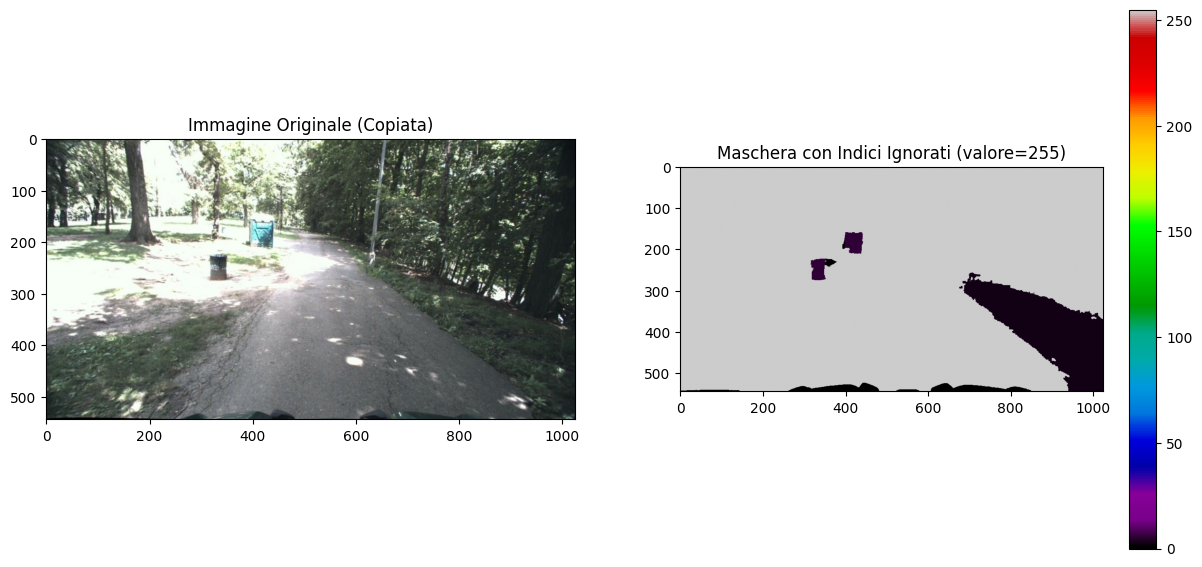

In [16]:
import os
import glob
import numpy as np
from PIL import Image
from tqdm import tqdm
import shutil

# --- 1. CONFIGURAZIONE ---

SOURCE_DATASET_PATH = "../../dataset/training/train"
# Cartella dedicata per questo esperimento
TARGET_IGNORE_INDEX_PATH = "../../dataset/training/train_ignore_index"

# Classi che, quando presenti, verranno "ignorate" nella maschera
CLASSES_TO_IGNORE = {1, 3, 7} # Le classi più comuni o dominanti
# Classi che vogliamo "isolare" e imparare
CLASSES_TO_ISOLATE = {4, 5} 
# Valore speciale per l'indice da ignorare. 255 è uno standard comune.
IGNORE_INDEX_VALUE = 255

def create_ignore_index_dataset():
    """
    Crea un dataset in cui le classi dominanti sono state sostituite
    nella maschera con un indice da ignorare.
    """
    
    # Setup della cartella di destinazione
    if os.path.exists(TARGET_IGNORE_INDEX_PATH):
        print(f"Elimino la vecchia cartella: '{TARGET_IGNORE_INDEX_PATH}'")
        shutil.rmtree(TARGET_IGNORE_INDEX_PATH)
    os.makedirs(TARGET_IGNORE_INDEX_PATH)

    print(f"Dati originali letti da: {SOURCE_DATASET_PATH}")
    print(f"Dati per 'Ignore Index' salvati in: {TARGET_IGNORE_INDEX_PATH}")
    print("-" * 50)
    
    all_sample_dirs = sorted(glob.glob(os.path.join(SOURCE_DATASET_PATH, "*")))
    
    generated_count = 0
    print("Inizio generazione del dataset 'Ignore Index'...")
    for sample_dir in tqdm(all_sample_dirs, desc="Processing samples"):
        mask_path = os.path.join(sample_dir, 'labels.png')
        if not os.path.exists(mask_path): continue
        
        mask_np = np.array(Image.open(mask_path))
        unique_classes = set(np.unique(mask_np))
        
        # CONDIZIONE: Processiamo solo le immagini che contengono ALMENO UNA
        # delle classi che vogliamo isolare.
        if not unique_classes.intersection(CLASSES_TO_ISOLATE):
            continue

        # --- Creazione della nuova maschera modificata ---
        new_mask = mask_np.copy()
        
        # Per ogni pixel, se la sua classe è nella lista da ignorare,
        # impostalo a IGNORE_INDEX_VALUE.
        for class_to_ignore in CLASSES_TO_IGNORE:
            new_mask[mask_np == class_to_ignore] = IGNORE_INDEX_VALUE
        
        # Copia l'immagine originale e salva la nuova maschera
        base_name = os.path.basename(sample_dir)
        dest_dir = os.path.join(TARGET_IGNORE_INDEX_PATH, f"{base_name}_ignored")
        os.makedirs(dest_dir, exist_ok=True)
        
        # Copia l'immagine RGB originale
        shutil.copy(os.path.join(sample_dir, 'rgb.jpg'), os.path.join(dest_dir, 'rgb.jpg'))
        
        # Salva la maschera modificata
        Image.fromarray(new_mask.astype(np.uint8)).save(os.path.join(dest_dir, 'labels.png'))
        
        generated_count += 1
        
    print(f"\nProcesso completato. Creati {generated_count} campioni nella cartella '{TARGET_IGNORE_INDEX_PATH}'.")

# Esegui la funzione per creare il dataset
create_ignore_index_dataset()

# (Opzionale) Visualizziamo un esempio per verificare
def visualize_ignore_index_sample():
    sample_to_check_path = glob.glob(os.path.join(TARGET_IGNORE_INDEX_PATH, "*"))[0]
    
    img = Image.open(os.path.join(sample_to_check_path, 'rgb.jpg'))
    mask = Image.open(os.path.join(sample_to_check_path, 'labels.png'))
    
    plt.figure(figsize=(15, 7))
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Immagine Originale (Copiata)")
    
    plt.subplot(1, 2, 2)
    # Mostriamo la maschera. I pixel con valore 255 appariranno di un colore diverso
    # a seconda della colormap (spesso bianco o nero).
    plt.imshow(np.array(mask), cmap='nipy_spectral') 
    plt.title("Maschera con Indici Ignorati (valore=255)")
    plt.colorbar()
    plt.show()

visualize_ignore_index_sample()

In [ ]:
ORIGINAL_DATA_PATH = "../../dataset/training/train"
GENERATED_DATA_PATH = "../../dataset/training/train_generated_pixel_balanced"
TARGET_IGNORE_INDEX_PATH = "../../dataset/training/train_ignore_index"

dirs_original = sorted(glob.glob(os.path.join(ORIGINAL_DATA_PATH, "*")))
dirs_generated = sorted(glob.glob(os.path.join(GENERATED_DATA_PATH, "*")))
dirs_igidx_generated = sorted(glob.glob(os.path.join(TARGET_IGNORE_INDEX_PATH, "*")))

all_dirs = [d for d in (dirs_original + dirs_generated + dirs_igidx_generated) if os.path.isdir(d)]

# Filtra eventuali file non voluti (come sempre)
all_dirs = [d for d in all_dirs if os.path.isdir(d) and not os.path.basename(d).startswith('__')]

print(f"Dataset totale per il training composto da:")
print(f"- {len(dirs_original)} campioni originali")
print(f"- {len(dirs_generated)} campioni generati")
print(f"- {len(dirs_igidx_generated)} campioni generati con Ignore Index")
print(f"-> Totale: {len(all_dirs)} campioni")

class_names = []
for idx in range(9):
    class_names.append(f"Classe {idx}")

def calculate_class_distribution_gpu(dataset, device):
  """
  Calcola il numero di pixel per ogni classe, usando la GPU se disponibile.
  VERSione AGGIORNATA per ignorare i valori > num_classes.
  """
  num_classes = 9 # Da 0 a 8
  IGNORE_INDEX = 255 # Il nostro valore speciale

  class_counts = torch.zeros(num_classes, dtype=torch.int64, device=device)

  # Se hai problemi di multiprocessing su Windows, imposta num_workers=0
  loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=2)

  for _, masks_batch in tqdm(loader, desc="Analisi distribuzione classi (GPU)"):
    masks_batch = masks_batch.to(device)

    for i in range(masks_batch.shape[0]):
      mask = masks_batch[i]
      
      # --- MODIFICA CHIAVE ---
      # 1. Appiattisci la maschera
      flat_mask = mask.flatten()
      
      # 2. Seleziona SOLO i pixel che NON sono l'ignore_index
      # In questo modo, i valori 255 vengono scartati prima del conteggio.
      valid_pixels = flat_mask[flat_mask != IGNORE_INDEX]
      
      # 3. Esegui bincount solo sui pixel validi
      # Se una maschera contenesse solo pixel da ignorare, valid_pixels sarebbe vuoto.
      if valid_pixels.numel() > 0:
          # bincount ora non vedrà mai un valore > 8
          class_counts += torch.bincount(valid_pixels, minlength=num_classes)

  # sulla CPU per NumPy e Matplotlib
  return class_counts.cpu()

# Crea un dataset a partire dai percorsi combinati e analizza la distribuzione
combined_dataset = SegmentationDataset(sample_dirs=all_dirs)
distribution_analysis(combined_dataset, class_names)



Dataset totale per il training composto da:
- 931 campioni originali
- 4473 campioni generati
- 196 campioni generati con Ignore Index
-> Totale: 5600 campioni


Analisi distribuzione classi (GPU):   0%|          | 0/88 [00:00<?, ?it/s]